# 17 · MPPI는 비용 차이를 얼마나 세밀하게 행동으로 옮기는가

> 15에서 MPPI는 식보다 1~2 cm 멀리 멈췄고, 16에서는 수 cm의 η 차이가 약 1 cm의 이격 차이로만 나타났다. MPPI의 샘플 잡음 σ, 온도 β, 후보 수 K가 이 "해상도"를 어떻게 정할까?

| | |
|---|---|
| **이 노트의 질문** | 샘플 잡음 σ, 온도 β, 후보 수 K가 (1) 유효 샘플 수 ESS = (Σw)²/Σw², (2) 이격의 잡음 편향, (3) "얼마나 작은 η 차이까지 이격 차이로 구별되는가"를 어떻게 바꾸는가 |
| **최종 목표** | ESS가 무엇이고 β와 비용 크기에 따라 왜 줄거나 느는지 설명할 수 있다. MPPI가 균형 이격보다 멀리 멈추는 잡음 편향의 원인과 σ·K와의 관계를 설명할 수 있다. 방향별 질량 효과(수 cm의 η 차이)가 행동으로 구별되려면 어떤 조건이 필요한지 수치로 말할 수 있다 |
| **연구의 어느 결정과 연결되는가** | 15의 잡음 편향(1~2.4 cm), 16의 "η 차이가 잡음에 묻힘", 22의 cuRobo 설정 해석 |
| **이 노트에서 바꾸는 요인** | MPPI 설정 σ, β, K (나머지 장면·비용은 15·16과 같다). 3절에서만 η 차이를 일부러 키운다 |

**지금 위치:** 01~13 기초·MPPI·프로젝트 → 14 움직이는 사람 → 15 η와 w → 16 방향별 질량 → **17 ESS** → 18 형상 비용 합치기 → 19 필요 이격 거리 → 20 안전 필터 → 21 지연 → 22 cuRobo 확인

**필요한 것:** [05](05_mppi_basics.ipynb) MPPI 가중평균, [15](15_eta_vs_weight.ipynb) 1D 장면과 잡음 편향, [16](16_directional_mass.ipynb) 팔 옆 자세 · **예상 시간:** 50분

**참고:** cuRobo 프로토타입 설정은 후보 400, 반복 5, β 0.1, BEST 출력(가중치가 가장 큰 후보 하나)이다. 이 노트는 05·06의 가중평균 MPPI(β = 1)로 진행하고, BEST 출력과의 비교는 22에서 한다.

## 복습 퀴즈

<details><summary>1. 05의 MPPI에서 후보 k의 가중치는 비용 J_k로 어떻게 정해지나?</summary>

$w_k \propto \exp(-(J_k - J_{min})/\beta)$. 비용이 낮을수록 가중치가 크고, β가 작을수록 가장 싼 후보에 몰린다. 다음 평균 계획은 가중치로 낸 후보들의 평균이다.
</details>

<details><summary>2. 15의 1D 장면에서 MPPI(σ = 2)가 멈춘 이격은 식 d_eq보다 가까웠나, 멀었나? 원인은?</summary>

**1~2 cm 멀었다.** σ를 줄이면 식에 다가갔으므로 원인은 샘플 잡음이었다. 사람 쪽으로 흔들린 후보가 비싸져서 가중평균이 물러난다.
</details>

<details><summary>3. 16의 팔 옆 자세에서 (iii) 잠금 있음/없음의 η 차이(가장 가까운 순간 약 3.5 cm)는 팔 최소 이격 차이로 얼마나 나타났나?</summary>

**약 1 cm**(평균 +1.00 cm). seed 범위가 겹쳐 구별되지 않았다.
</details>

In [1]:
import sys, time
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))          # 노트 폴더 (common14 패키지)
import numpy as np
from functools import partial
from scipy.optimize import minimize, brentq
from common14 import *
from common14 import scene as S
from common14.pose import make_pose, pose_gaps, pose_nearest, pose_cost_directional, draw_pose
plt = setup_plot()

def rng_str(vals, fmt='%.3f'):
    vals = [v for v in vals if v is not None]
    return '-' if not vals else (fmt + '~' + fmt) % (min(vals), max(vals))

print('기본 MPPI 설정: K = %d, T = %d, 반복 %d, σ = %.1f m/s², β = %.1f, 출력 = 가중평균' % (S.K, S.T, S.N_ITERS, S.SIGMA, S.BETA))

기본 MPPI 설정: K = 400, T = 30, 반복 5, σ = 2.0 m/s², β = 1.0, 출력 = 가중평균


## 1. 문제 — 가중치가 몇 개의 후보에 실려 있는가

### 문제
MPPI는 후보 K개를 흔들어 비용을 매기고, $w_k \propto \exp(-(J_k - J_{min})/\beta)$로 가중평균한다. 두 극단을 생각해 보자.
- **가중치가 후보 하나에 몰리면**(β가 아주 작거나 비용 차이가 아주 크면) 평균은 그 한 후보다. 그 후보는 잡음으로 뽑힌 것이라 스텝마다 크게 바뀐다. 명령이 흔들린다.
- **가중치가 모든 후보에 고르면**(β가 크거나 비용 차이가 작으면) 평균은 잡음의 평균, 즉 지금 계획과 거의 같다. 비용이 주는 정보가 거의 반영되지 않는다.

그 사이 어디에 있는지를 하나의 수로 나타낸 것이 **유효 샘플 수(ESS)**다.

$$\mathrm{ESS} = \frac{(\sum_k w_k)^2}{\sum_k w_k^2}$$

가중치가 모두 같으면 ESS = K, 하나에 몰리면 ESS = 1이다. "가중치가 실제로 몇 개 후보에 실려 있는가"로 읽는다. 공통 모듈의 `ess(w)`가 이 식이고, 실행 함수는 매 스텝 마지막 반복의 ESS를 기록한다.

In [2]:
for name, w in [('고른 4개', [0.25, 0.25, 0.25, 0.25]), ('하나에 몰림', [1.0, 0.0, 0.0, 0.0]),
                ('둘에 반반', [0.5, 0.5, 0.0, 0.0]), ('0.7 / 0.1 / 0.1 / 0.1', [0.7, 0.1, 0.1, 0.1])]:
    print('%-22s ESS = %.2f' % (name, ess(np.array(w))))

고른 4개                  ESS = 4.00
하나에 몰림                 ESS = 1.00
둘에 반반                  ESS = 2.00
0.7 / 0.1 / 0.1 / 0.1  ESS = 1.92


### ESS는 무엇으로 정해지나 — 비용의 흩어짐과 β의 비

후보 비용이 평균 주위로 표준편차 s만큼 흩어져 있다고 하자. 가중치는 $\exp(-J/\beta)$라서 정해지는 것은 **s/β**뿐이다. 비용이 정규분포로 흩어져 있으면

$$\frac{\mathrm{ESS}}{K} \approx \exp\left(-(s/\beta)^2\right)$$

이다(정규분포의 $E[e^{-J/\beta}]^2 / E[e^{-2J/\beta}]$). 아래에서 후보 400개의 비용을 정규분포로 뽑아 직접 확인한다.
- β를 줄이면 s/β가 커져 ESS가 줄어든다.
- 비용 차이가 커지면(σ가 커서 후보가 더 다르거나, 비용 w가 커서) s가 커져 ESS가 줄어든다.

s/β = 0.3 → ESS 365 (식 366)
s/β = 1.0 → ESS 104 (식 147)
s/β = 2.0 → ESS 5 (식 7)


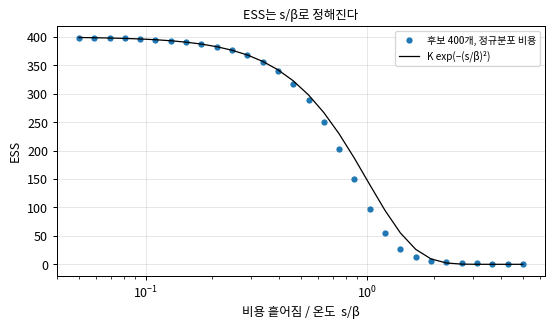

In [3]:
rng = np.random.default_rng(0)
z = rng.standard_normal(S.K)
ratio = np.logspace(-1.3, 0.7, 30)
ess_num = [ess(softmax_weights(r * z, 1.0)) for r in ratio]
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.semilogx(ratio, ess_num, 'o', ms=4, label='후보 400개, 정규분포 비용')
ax.semilogx(ratio, S.K * np.exp(-ratio ** 2), 'k-', lw=1, label='K exp(−(s/β)²)')
ax.set_xlabel('비용 흩어짐 / 온도  s/β'); ax.set_ylabel('ESS'); ax.legend(fontsize=8)
ax.set_title('ESS는 s/β로 정해진다', fontsize=10)
plt.show()
for r in (0.3, 1.0, 2.0):
    print('s/β = %.1f → ESS %.0f (식 %.0f)' % (r, ess(softmax_weights(r * z, 1.0)), S.K * np.exp(-r ** 2)))

s/β가 0.3이면 ESS가 K에 가깝고(365), 1이면 약 4분의 1(104), 2이면 한 자릿수(5)다. 식은 s/β ≈ 1 근처에서 조금 크게 나오지만(147) 모양은 같다. **ESS는 β 하나로 정해지지 않는다.** 같은 β = 1이라도 비용이 얼마나 흩어지는지(장면, w, σ)에 따라 ESS가 크게 달라진다.

**예측해 보기:** 15의 1D 장면에서 β를 1 → 0.1로 줄이면 ESS와 명령 변화량은 어떻게 될까? σ를 2 → 0.25로 줄이면?

## 2. 실험 1 — 1D 정지 장면에서 σ, β, K 바꾸기

### 장면
15의 1D 장면 그대로다. 로봇은 x축 위로만 움직이고(`line=True`, y 방향 탐색 폭 0), 목표는 몸통 뒤쪽 표면 (1.50, 0)이다. 사람 비용은 사람 전체에 균일 η = 0.10 m라서 분절 구별은 없고, 로봇 앞의 가장 가까운 면은 팔 끝(로봇 x = 0.805 m에서 간격 0)이다. 5 s 동안 달린 뒤 **마지막 1 s의 평균 간격**을 멈춘 이격으로 잰다.

w는 두 가지다. w = 100(기본)과 w = 18.75(15의 가장 가벼운 설정, 15에서 σ = 0.25일 때 이상 결과가 나온 값).

### 잡음 편향의 기준
- **식 d_eq**(15의 2절): "30칸 내내 멈춰 있는 계획"끼리 비교한 균형 이격.
- **잡음 없는 최적해**(15의 4.1절): 같은 MPC 문제(30칸, ±4 m/s² 한계)를 잡음 없이 풀었을 때 첫 입력이 0이 되는 자리.

MPPI의 잡음 때문에 생긴 차이만 보려면 잡음 없는 최적해를 기준으로 삼아야 한다. 식과 잡음 없는 최적해 자체도 조금 다르기 때문이다(아래 출력). 이 노트의 **잡음 편향 = 멈춘 이격 − 잡음 없는 최적해**이고, 식과의 차이도 함께 적는다.

측정은 seed 8개다.
- 멈춘 이격과 그 seed 간 표준편차(흩어짐)
- 마지막 1 s의 ESS 평균(K = 400 중 몇 개)
- 명령 변화량 |u_t − u_{t−1}|의 마지막 1 s 평균(멈춘 상태에서 명령이 얼마나 흔들리는가)

In [4]:
GOAL_1D = np.array([S.TORSO_C[0] + S.TORSO_R, 0.0])      # (1.50, 0)
X_FRONT = S.ARM_B[0] - S.ARM_R - S.ROBOT_R               # 팔 끝과의 간격이 0이 되는 로봇 x (0.805 m)
C_PULL = 2 * (S.W_GOAL + S.W_TERM / S.T)
L_1D = GOAL_1D[0] - X_FRONT

def d_eq_line(eta, w):
    # 15의 1D 균형 이격 식
    return eta * (w - C_PULL * L_1D) / (w + C_PULL * eta)

def first_input(x0, eta, w):
    # x0에 멈춰 있는 로봇에서 30칸 가속도를 잡음 없이 최적화했을 때 첫 입력 (15의 4.1절과 같음)
    def J(a):
        U = np.stack([a, np.zeros(S.T)], -1)
        P, V = rollout(np.array([x0, 0.0]), np.zeros(2), U)
        return (goal_cost(P, V, U, GOAL_1D) + human_cost_uniform(P[1:], np.zeros((S.T, 2)), eta, w)).sum()
    return minimize(J, np.zeros(S.T), method='L-BFGS-B', bounds=[(-S.U_MAX, S.U_MAX)] * S.T).x[0]

def noise_free(eta, w):
    th = d_eq_line(eta, w)
    return X_FRONT - brentq(lambda x: first_input(x, eta, w), X_FRONT - th - 0.03, X_FRONT - th + 0.03, xtol=1e-6)

W_LIST = (100.0, 18.75)
REF = {w: dict(deq=d_eq_line(S.ETA0, w), nf=noise_free(S.ETA0, w)) for w in W_LIST}
for w in W_LIST:
    print('w = %6.2f: 식 d_eq %.4f m, 잡음 없는 최적해 %.4f m (차이 %+.4f m)' % (w, REF[w]['deq'], REF[w]['nf'], REF[w]['nf'] - REF[w]['deq']))

def run_1d(w, seed, sigma=S.SIGMA, beta=S.BETA, K=S.K, steps=S.STEPS):
    r = run_mpc_opts(partial(human_cost_uniform, eta=S.ETA0, w=w), goal=GOAL_1D, seed=seed, sigma=sigma, beta=beta, K=K,
                     line=True, steps=steps)
    c = clearance_series(r['traj'], r['person'])
    return dict(c=c, stop=c[-20:].mean(), ess=r['ess'][-20:].mean(), du=np.abs(np.diff(r['us'][:, 0]))[-20:].mean())

w = 100.00: 식 d_eq 0.0974 m, 잡음 없는 최적해 0.0984 m (차이 +0.0010 m)
w =  18.75: 식 d_eq 0.0861 m, 잡음 없는 최적해 0.0916 m (차이 +0.0055 m)


### 2.1 σ와 β 격자

σ = 0.25, 0.5, 1, 2, 3 m/s²와 β = 0.1, 0.3, 1, 3, 10을 모두 조합한다(K = 400). 먼저 하나씩 바꾼 줄(β = 1에서 σ, σ = 2에서 β)을 표로 보고, 격자 전체는 그림으로 본다.

In [5]:
SIGMAS1, BETAS1, SEEDS1 = (0.25, 0.5, 1.0, 2.0, 3.0), (0.1, 0.3, 1.0, 3.0, 10.0), range(8)
t0 = time.time()
G1 = {(w, sg, b): [run_1d(w, s, sigma=sg, beta=b) for s in SEEDS1] for w in W_LIST for sg in SIGMAS1 for b in BETAS1}
print('실행 시간 %.0f s\n' % (time.time() - t0))

def summary(rs, w):
    st = np.array([r['stop'] for r in rs])
    return dict(rng=rng_str(st, '%.4f'), mean=st.mean(), sd=st.std(), b_deq=st.mean() - REF[w]['deq'], b_nf=st.mean() - REF[w]['nf'],
                ess=np.mean([r['ess'] for r in rs]), du=np.mean([r['du'] for r in rs]))

HEAD = '%-12s | %-16s | %-8s | %-9s | %-11s | %-6s | %-6s' % ('설정', '멈춘 이격 [m]', '−식', '−잡음없음', 'seed 흩어짐', 'ESS', '명령 변화')
ROW = '%-12s | %-16s | %+.4f  | %+.4f   | %.4f      | %-6.0f | %.2f'
for w in W_LIST:
    print('w = %.2f (식 %.4f, 잡음 없는 최적해 %.4f)' % (w, REF[w]['deq'], REF[w]['nf']))
    print(HEAD)
    for sg in SIGMAS1:
        m = summary(G1[(w, sg, 1.0)], w)
        print(ROW % ('σ %.2f, β 1' % sg, m['rng'], m['b_deq'], m['b_nf'], m['sd'], m['ess'], m['du']))
    for b in BETAS1:
        m = summary(G1[(w, 2.0, b)], w)
        print(ROW % ('σ 2, β %g' % b, m['rng'], m['b_deq'], m['b_nf'], m['sd'], m['ess'], m['du']))
    print()

실행 시간 502 s

w = 100.00 (식 0.0974, 잡음 없는 최적해 0.0984)
설정           | 멈춘 이격 [m]        | −식       | −잡음없음     | seed 흩어짐    | ESS    | 명령 변화 
σ 0.25, β 1  | 0.0949~0.1049    | +0.0018  | +0.0007   | 0.0029      | 161    | 0.26
σ 0.50, β 1  | 0.1001~0.1040    | +0.0048  | +0.0038   | 0.0012      | 83     | 0.69
σ 1.00, β 1  | 0.1033~0.1111    | +0.0108  | +0.0098   | 0.0027      | 35     | 1.62
σ 2.00, β 1  | 0.1074~0.1178    | +0.0167  | +0.0156   | 0.0038      | 13     | 1.86
σ 3.00, β 1  | 0.1086~0.1218    | +0.0195  | +0.0184   | 0.0045      | 9      | 2.27
σ 2, β 0.1   | 0.1037~0.1185    | +0.0128  | +0.0117   | 0.0045      | 2      | 3.44
σ 2, β 0.3   | 0.1001~0.1171    | +0.0097  | +0.0087   | 0.0054      | 3      | 3.07
σ 2, β 1     | 0.1074~0.1178    | +0.0167  | +0.0156   | 0.0038      | 13     | 1.86
σ 2, β 3     | 0.1165~0.1297    | +0.0259  | +0.0249   | 0.0041      | 45     | 1.16
σ 2, β 10    | 0.1356~0.1560    | +0.0504  | +0.0494   | 0.0058      | 127    | 0.72

w = 18.75

**β를 바꾸면 (σ = 2):** β를 0.1 → 10으로 키우면 ESS가 2 → 127(w = 100), 2 → 220(w = 18.75)으로 늘고, 명령 변화량은 3.44 → 0.72, 3.18 → 0.54로 줄었다. **β가 작을수록 ESS가 작고 명령이 더 흔들린다.** 편향은 β = 0.1~0.3에서 가장 작고(w = 100: +0.9~+1.2 cm, w = 18.75: +0.1 cm), β를 키울수록 커졌다(β = 10에서 +4.9, +5.6 cm).

**σ를 바꾸면 (β = 1):**
- w = 100: σ를 0.25 → 3으로 키우면 잡음 편향이 +0.07 → +0.38 → +0.98 → +1.56 → +1.84 cm로 커졌다. ESS는 161 → 9로 줄었다. σ가 크면 후보들의 비용이 더 다르므로(s가 커서) ESS가 준다.
- w = 18.75: σ ≥ 0.5에서는 σ와 함께 편향이 커졌다(−0.44 → +0.14 → +0.54 → +0.75 cm). σ = 0.25에서만 다시 +0.58 cm로 커지고 seed 흩어짐도 0.36 cm로 σ = 0.5(0.13 cm)보다 컸다. 15에서 본 이상 결과가 seed 8개에서도 나왔다(2.3절).

**w를 바꾸면:** 같은 σ = 2, β = 1에서 ESS는 w = 100이 13, w = 18.75가 25다. 비용 w가 크면 후보 비용이 더 흩어져 ESS가 작다.

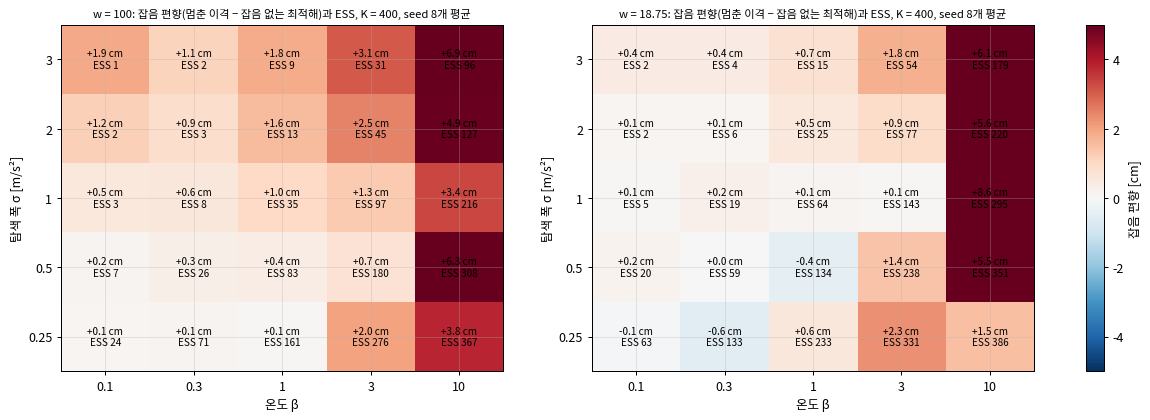

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(15, 5))
for ax, w in zip(axs, W_LIST):
    B = np.array([[summary(G1[(w, sg, b)], w)['b_nf'] * 100 for b in BETAS1] for sg in SIGMAS1])
    E = np.array([[summary(G1[(w, sg, b)], w)['ess'] for b in BETAS1] for sg in SIGMAS1])
    im = ax.imshow(B, cmap='RdBu_r', vmin=-5, vmax=5, origin='lower', aspect='auto')
    for i in range(len(SIGMAS1)):
        for j in range(len(BETAS1)):
            ax.text(j, i, '%+.1f cm\nESS %.0f' % (B[i, j], E[i, j]), ha='center', va='center', fontsize=8)
    ax.set_xticks(range(len(BETAS1))); ax.set_xticklabels(['%g' % b for b in BETAS1]); ax.set_xlabel('온도 β')
    ax.set_yticks(range(len(SIGMAS1))); ax.set_yticklabels(['%g' % s for s in SIGMAS1]); ax.set_ylabel('탐색 폭 σ [m/s²]')
    ax.set_title('w = %g: 잡음 편향(멈춘 이격 − 잡음 없는 최적해)과 ESS, K = 400, seed 8개 평균' % w, fontsize=9)
fig.colorbar(im, ax=axs, fraction=0.02, label='잡음 편향 [cm]')
plt.show()

격자 전체를 보면 편향이 커지는 길이 두 가지다.
- **σ가 클 때(ESS와 무관하게):** w = 100에서 가장 작은 β = 0.1 열만 봐도 σ = 0.25 → 3에서 +0.1 → +1.9 cm로 커진다(ESS는 24 → 1). 후보가 사람 쪽으로 크게 흔들리고 그 후보를 가중평균이 피하는, 15에서 본 잡음 편향이다.
- **ESS가 클 때:** β = 3~10 열이나 σ가 작은 칸에서 ESS가 200을 넘은 칸은 11개다. 편향은 +0.6~+8.6 cm였고, 그중 10칸이 +1.4 cm 이상이었다. 이 영역에서는 가중치가 많은 후보에 퍼져 있어서, 한 번의 갱신에 비용 차이가 적게 반영된다.

w = 18.75의 β ≤ 1, σ ≤ 1 칸들은 편향이 −0.6~+0.6 cm로 작다. 그 사이에 음의 편향(−0.4, −0.6 cm)도 있다. 둘 다 ESS가 130 안팎인 칸이다.

### 2.2 후보 수 K

σ = 2, β = 1에서 K = 50, 100, 400, 1600으로 바꾼다. K를 늘리면 같은 σ로 더 많은 후보를 보므로, 가중평균의 seed 간 흩어짐이 줄어들 것이다.

In [7]:
KS = (50, 100, 400, 1600)
t0 = time.time()
GK = {(w, K): (G1[(w, 2.0, 1.0)] if K == S.K else [run_1d(w, s, K=K) for s in SEEDS1]) for w in W_LIST for K in KS}
print('실행 시간 %.0f s\n' % (time.time() - t0))
for w in W_LIST:
    print('w = %.2f' % w)
    print(HEAD.replace('설정        ', 'K           '))
    for K in KS:
        m = summary(GK[(w, K)], w)
        print(ROW % ('K %d' % K, m['rng'], m['b_deq'], m['b_nf'], m['sd'], m['ess'], m['du']))
    print()

실행 시간 89 s

w = 100.00
K              | 멈춘 이격 [m]        | −식       | −잡음없음     | seed 흩어짐    | ESS    | 명령 변화 
K 50         | 0.0951~0.1489    | +0.0278  | +0.0268   | 0.0184      | 3      | 2.82
K 100        | 0.1048~0.1268    | +0.0200  | +0.0189   | 0.0074      | 4      | 2.37
K 400        | 0.1074~0.1178    | +0.0167  | +0.0156   | 0.0038      | 13     | 1.86
K 1600       | 0.1083~0.1116    | +0.0122  | +0.0112   | 0.0009      | 47     | 1.45

w = 18.75
K              | 멈춘 이격 [m]        | −식       | −잡음없음     | seed 흩어짐    | ESS    | 명령 변화 
K 50         | 0.0751~0.1242    | +0.0184  | +0.0129   | 0.0132      | 4      | 2.57
K 100        | 0.0878~0.1081    | +0.0130  | +0.0075   | 0.0058      | 7      | 2.36
K 400        | 0.0932~0.0987    | +0.0109  | +0.0054   | 0.0016      | 25     | 1.71
K 1600       | 0.0939~0.0979    | +0.0099  | +0.0045   | 0.0013      | 98     | 1.03



**K를 늘리면 seed 간 흩어짐이 줄었다.**
- w = 100: K 50 → 100 → 400 → 1600에서 표준편차 1.84 → 0.74 → 0.38 → 0.09 cm, 범위는 0.0951~0.1489 → 0.1083~0.1116 m로 좁아졌다.
- w = 18.75: 표준편차 1.32 → 0.58 → 0.16 → 0.13 cm.

편향 자체도 K를 늘리면 작아졌지만(w = 100: +2.68 → +1.12 cm, w = 18.75: +1.29 → +0.45 cm) 0이 되지는 않았다. ESS는 K와 거의 비례해 늘었다(w = 100: 3 → 47, K의 약 3%). 명령 변화량도 K를 늘리면 줄었다(w = 100: 2.82 → 1.45).

### 2.3 15의 이상 결과 다시 보기 — w = 18.75, σ = 0.25

15에서 w = 18.75일 때 σ를 2 → 1 → 0.5로 줄이면 식(0.086 m)에 다가갔는데, σ = 0.25에서는 다시 멀어졌다(0.096~0.102 m, ESS 233). 15는 seed 4개였고 기준이 식이었다. 여기서는 세 가지를 확인한다.
1. 위 격자(seed 8개)에서 같은 현상이 나오는지, 그리고 기준을 잡음 없는 최적해로 바꾸면 어떻게 보이는지
2. 느리게 수렴하는 중이라서 그런지: 같은 설정(σ = 0.25, 0.5)과, 격자에서 ESS가 크고 편향이 컸던 두 설정(w = 18.75의 σ 0.25·β 3, w = 100의 σ 2·β 10)을 40 s(800스텝) 동안 돌려 시간에 따른 이격과 4~5 s의 속력을 본다
3. 격자 전체에서 잡음 편향과 seed 흩어짐이 ESS와 어떤 관계인지

In [8]:
t0 = time.time()
LONG_SET = [(18.75, 0.25, 1.0), (18.75, 0.5, 1.0), (18.75, 0.25, 3.0), (100.0, 2.0, 10.0)]
LONG = {c: [run_1d(c[0], s, sigma=c[1], beta=c[2], steps=800) for s in SEEDS1] for c in LONG_SET}
print('실행 시간 %.0f s\n' % (time.time() - t0))
print('시각 t까지 마지막 1 s 평균 간격 (seed 8개 평균) [m]. 잡음 없는 최적해: w = 100 %.4f, w = 18.75 %.4f' % (REF[100.0]['nf'], REF[18.75]['nf']))
for (w, sg, b), rs in LONG.items():
    at = lambda t: np.mean([r['c'][int(t / S.DT) - 20:int(t / S.DT)].mean() for r in rs])
    v45 = np.mean([np.abs(np.diff(r['c'][80:101])).mean() / S.DT for r in rs])
    print('w = %6.2f, σ = %.2f, β = %-2g (5 s ESS %3.0f): ' % (w, sg, b, summary(G1[(w, sg, b)], w)['ess'])
          + '  '.join('t = %2d s: %.4f' % (t, at(t)) for t in (5, 10, 20, 30, 40))
          + ' | 40 s 편향 %+.1f cm | 4~5 s 속력 %.3f m/s' % ((at(40) - REF[w]['nf']) * 100, v45))

실행 시간 323 s

시각 t까지 마지막 1 s 평균 간격 (seed 8개 평균) [m]. 잡음 없는 최적해: w = 100 0.0984, w = 18.75 0.0916
w =  18.75, σ = 0.25, β = 1  (5 s ESS 233): t =  5 s: 0.0973  t = 10 s: 0.0954  t = 20 s: 0.0954  t = 30 s: 0.0955  t = 40 s: 0.0966 | 40 s 편향 +0.5 cm | 4~5 s 속력 0.008 m/s
w =  18.75, σ = 0.50, β = 1  (5 s ESS 134): t =  5 s: 0.0871  t = 10 s: 0.0871  t = 20 s: 0.0870  t = 30 s: 0.0865  t = 40 s: 0.0877 | 40 s 편향 -0.4 cm | 4~5 s 속력 0.015 m/s
w =  18.75, σ = 0.25, β = 3  (5 s ESS 331): t =  5 s: 0.1142  t = 10 s: 0.1228  t = 20 s: 0.1318  t = 30 s: 0.1290  t = 40 s: 0.1386 | 40 s 편향 +4.7 cm | 4~5 s 속력 0.011 m/s
w = 100.00, σ = 2.00, β = 10 (5 s ESS 127): t =  5 s: 0.1474  t = 10 s: 0.1501  t = 20 s: 0.1481  t = 30 s: 0.1509  t = 40 s: 0.1514 | 40 s 편향 +5.3 cm | 4~5 s 속력 0.031 m/s


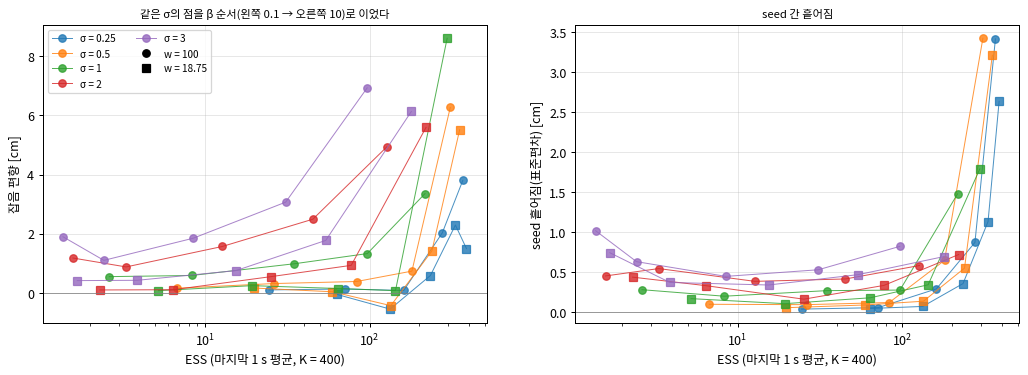

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4.3))
for w, mk in [(100.0, 'o'), (18.75, 's')]:
    for sg, col in zip(SIGMAS1, ['C0', 'C1', 'C2', 'C3', 'C4']):
        ms = [summary(G1[(w, sg, b)], w) for b in BETAS1]
        axs[0].plot([m['ess'] for m in ms], [m['b_nf'] * 100 for m in ms], mk + '-', color=col, ms=6, lw=0.8, alpha=0.8,
                    label='σ = %g' % sg if w == 100.0 else None)
        axs[1].plot([m['ess'] for m in ms], [m['sd'] * 100 for m in ms], mk + '-', color=col, ms=6, lw=0.8, alpha=0.8)
for ax, yl in zip(axs, ['잡음 편향 [cm]', 'seed 흩어짐(표준편차) [cm]']):
    ax.set_xscale('log'); ax.set_xlabel('ESS (마지막 1 s 평균, K = 400)'); ax.set_ylabel(yl); ax.axhline(0, color='gray', lw=0.6)
axs[0].plot([], [], 'ko', label='w = 100'); axs[0].plot([], [], 'ks', label='w = 18.75')
axs[0].legend(fontsize=8, ncol=2); axs[0].set_title('같은 σ의 점을 β 순서(왼쪽 0.1 → 오른쪽 10)로 이었다', fontsize=9)
axs[1].set_title('seed 간 흩어짐', fontsize=9)
plt.show()

**1. 같은 현상이 나오는가:** 나왔다. w = 18.75, β = 1에서 σ = 0.25는 0.0918~0.1031 m(잡음 없는 최적해보다 +0.58 cm), σ = 0.5는 0.0857~0.0893 m(−0.44 cm)였다. **기준을 바꾸면 그림이 조금 달라진다.** w = 18.75에서는 잡음 없는 최적해(0.0916)가 식(0.0861)보다 0.55 cm 멀다(w = 100에서는 0.10 cm). 그래서 15에서 "σ = 0.5에서 식에 닿았다"는 결과는 잡음 없는 최적해보다 0.44 cm 가까이 멈춘 것이었다.

**2. 느리게 수렴하는 중인가:** 아니다. σ = 0.25, β = 1은 5 s에 0.0973, 10~30 s에 0.0954~0.0955, 40 s에 0.0966 m였다(40 s에도 잡음 없는 최적해보다 +0.5 cm, 4~5 s 속력 0.008 m/s). σ = 0.5는 0.0865~0.0877 m(−0.4 cm)로 그대로였다. 격자에서 ESS가 크고 편향이 컸던 두 설정도 다가오는 중이 아니었다. 4~5 s 속력은 0.011, 0.031 m/s로 거의 멈춰 있었다. 40 s의 편향은 w = 18.75, σ 0.25·β 3에서 +4.7 cm, w = 100, σ 2·β 10에서 +5.3 cm로 남았다. σ 0.25·β 3은 5 s 0.1142 → 40 s 0.1386 m로 오히려 더 멀어졌다. **β가 클 때의 편향은 5 s 안에 다 오지 못해서 생긴 것이 아니다.**

**3. ESS와의 관계(그림):**
- 왼쪽: 모든 σ에서 β를 키우면(선의 오른쪽 끝으로 갈수록) 편향이 커졌다. 꺾이는 ESS는 σ마다 다르다. σ = 0.25~1은 약 150~200 이후에 꺾이고, σ = 2~3은 ESS 30~100에서 이미 커진다.
- 오른쪽: seed 흩어짐은 ESS가 100보다 작은 동안 0.1~0.5 cm(σ = 3에서만 1 cm까지)이다. ESS가 200 근처를 넘으면 커지기 시작해 최대 3.4 cm까지 커졌다.
- w = 18.75, σ = 0.25, β = 1은 ESS 233(K의 58%)으로 σ = 0.25 선이 꺾여 올라가는 곳에 있다(β 0.3: ESS 133, −0.6 cm → β 1: ESS 233, +0.6 cm → β 3: ESS 331, +2.3 cm). 같은 영역의 다른 칸도 비슷하다. w = 18.75의 σ 0.5·β 3은 ESS 238에 +1.4 cm, w = 100의 σ 0.25·β 3은 ESS 276에 +2.0 cm였다. 반면 w = 100의 σ 0.25·β 1은 ESS 161이고 편향이 +0.07 cm였다.

**15의 이상 결과에 대한 이 노트의 설명:** σ를 줄이면 후보가 덜 흔들려 σ 때문에 생기는 편향은 줄어든다. 그러나 후보들의 비용 차이(s)도 같이 작아져 s/β가 줄고, ESS가 커진다(w = 18.75, β = 1: σ 0.5에서 134 → σ 0.25에서 233). w = 18.75는 사람 비용이 약해서 w = 100보다 이 영역에 일찍(σ = 0.25에서) 들어간다. 그 영역에서는 편향과 seed 흩어짐이 다시 커진다. **σ와 β는 따로 정할 수 없고, ESS(= s/β)가 너무 크지 않도록 함께 정해야 한다.**

**설명하지 못한 것:** 음의 편향(w = 18.75의 σ 0.5·β 1에서 −0.44 cm, σ 0.25·β 0.3에서 −0.6 cm)이 왜 생기는지는 확인하지 않았다. 둘 다 ESS 130 안팎, w = 18.75에서만 나왔고, 40 s까지 그대로였다. ESS가 큰 영역에서 왜 바깥쪽으로 치우치는지도 이 노트에서 따로 확인하지 않았다.

## 3. 실험 2 — 해상도: η 차이가 얼마나 커야 이격 차이로 구별되는가

### 장면과 규칙
16의 "팔 옆 자세"를 그대로 쓴다(몸통 (1.274, 0.31), 팔은 왼쪽 아래로 경로와 24°, 로봇은 팔 아래에서 팔을 위로 민다). η는 16의 (iii)(방향별 환산질량, p = 1, 기본 u 정의 = 무게중심 방향)이다. 2D MPPI(`run_mpc_opts`, 기본값이면 14의 run_mpc와 같음, 사람 정지, 목표 (2.0, 0))로 돌린다.

**η 차이 키우기:** 팔이 잠긴 쪽(u·잠금 방향 > 0)이면 η를 다음처럼 바꾼다.

$$\eta = \eta_{자유}(\mathbf{u}) + k\,\big(\eta_{잠금}(\mathbf{u}) - \eta_{자유}(\mathbf{u})\big)$$

여기서 $\eta_{자유}$는 잠금 없이 계산한 η, $\eta_{잠금}$은 질량 4배로 계산한 η다. k = 1이면 16의 (iii)과 같고, k = 2, 3, 4이면 잠금 있음/없음의 η 차이가 그 배가 된다. 이것은 η 규칙을 일부러 바꾸는 것이므로 이 노트 안에서만 쓰고 common14의 기본값은 바꾸지 않는다.

**구별 기준:** "잠금 있음" 16개 seed의 팔 최소 이격이 모두 "잠금 없음" 16개 seed의 최댓값보다 크면 구별된다고 본다(seed 범위가 겹치지 않음). 같은 seed끼리 짝지은 차이도 함께 적는다.

σ = 0.5, 1, 2와 k = 1, 2, 3, 4의 격자다. 잠금 없음 자세에서도 다가오는 동안 팔 길이 방향으로 잠기는 구간이 있어 k에 따라 조금 바뀌므로, 칸마다 두 자세를 모두 돌린다.

In [10]:
ex, ey = np.array([1.0, 0.0]), np.array([0.0, 1.0])
MU_REF = float(reduced_mass(directional_mass(ex, 'torso')))          # 15의 기준 (몸통)
M_L = float(reduced_mass(directional_mass(-ey, 'arm')))             # 16의 (iii) 기준: 팔 수직 자유
ETA_L = S.ETA0 * M_L / MU_REF

def eta_iii(m_h):
    # 16의 (iii), p = 1: 사람 쪽 질량 m_h → 환산질량 → η
    return ETA_L * reduced_mass(m_h) / M_L

# 16의 팔 옆 자세
_t = np.radians(24.0)
SIDE_DIR = (-np.cos(_t), -np.sin(_t))
SIDE_C = (1.0 - make_pose((0.0, 0.31), SIDE_DIR)['com'][1][0], 0.31)
_sgn = +1 if ey @ make_pose(SIDE_C, SIDE_DIR, +1)['lock_dir'] > 0 else -1
POSES = {'잠금 있음': make_pose(SIDE_C, SIDE_DIR, _sgn), '잠금 없음': make_pose(SIDE_C, SIDE_DIR, -_sgn)}

def eta_scaled(P, pz, k, offset=(0.0, 0.0)):
    # 잠긴 쪽의 η 차이만 k배 한 규칙 (이 노트 안에서만 씀). 반환: gap, eta, 분절 번호
    gap, idx, u = pose_nearest(P, pz, offset)
    m_arm = 1.0 / np.einsum('...i,ij,...j->...', u, pz['inv']['arm'], u)        # 잠금 없이 계산한 팔 m_h
    m_torso = 1.0 / np.einsum('...i,ij,...j->...', u, pz['inv']['torso'], u)
    locked = (idx == 1) & (u @ pz['lock_dir'] > 1e-9)
    e_arm = eta_iii(m_arm) + k * locked * (eta_iii(S.ROM_LOCK_FACTOR * m_arm) - eta_iii(m_arm))
    return gap, np.where(idx == 0, eta_iii(m_torso), e_arm), idx

def cost_scaled(Pf, offsets, pz, k):
    gap, eta, _ = eta_scaled(Pf, pz, k, offsets)
    return eta_cost(gap, eta, S.W_HUMAN)

Pt = np.random.default_rng(1).uniform([-0.2, -0.5], [2.2, 0.6], (50, S.T, 2))
for lk, pz in POSES.items():
    d = np.abs(cost_scaled(Pt, np.zeros((S.T, 2)), pz, 1)
               - pose_cost_directional(Pt, np.zeros((S.T, 2)), pz, eta_of_mass=lambda m: ETA_L * m / M_L, reduced=True)).max()
    print('k = 1이 16의 (iii)과 같은지 (%s): 임의 점 1500개에서 비용 최대 차이 %.1e' % (lk, d))

k = 1이 16의 (iii)과 같은지 (잠금 있음): 임의 점 1500개에서 비용 최대 차이 1.8e-15
k = 1이 16의 (iii)과 같은지 (잠금 없음): 임의 점 1500개에서 비용 최대 차이 1.8e-15


In [11]:
SIG2, KSC, SEEDS2 = (0.5, 1.0, 2.0), (1, 2, 3, 4), range(16)

def run_side(lk, k, sigma, seed):
    pz = POSES[lk]
    r = run_mpc_opts(partial(cost_scaled, pz=pz, k=k), seed=seed, sigma=sigma)
    tr = r['traj']
    g = pose_gaps(tr, pz)[:, 1]
    j = int(np.argmin(g))
    return dict(clr=g.min(), eta=float(eta_scaled(tr[j:j + 1], pz, k)[1][0]), ymin=tr[:, 1].min(), x_close=tr[j, 0], traj=tr)

t0 = time.time()
G2 = {(sg, k, lk): [run_side(lk, k, sg, s) for s in SEEDS2] for sg in SIG2 for k in KSC for lk in POSES}
print('실행 시간 %.0f s\n' % (time.time() - t0))

print('%-5s %-3s | %-9s | %-21s | %-21s | %-9s | %-11s | %s' % ('σ', 'k', 'Δη [cm]', '잠금 있음 이격 (평균)', '잠금 없음 이격 (평균)', '평균 차이', '범위 사이', '같은 seed 차이: 양수 개수, 범위 [cm]'))
RES2 = {}
for sg in SIG2:
    for k in KSC:
        A, B = G2[(sg, k, '잠금 있음')], G2[(sg, k, '잠금 없음')]
        a, b = np.array([r['clr'] for r in A]), np.array([r['clr'] for r in B])
        de = np.mean([r['eta'] for r in A]) - np.mean([r['eta'] for r in B])
        pd = (a - b) * 100
        RES2[(sg, k)] = dict(de=de, diff=a.mean() - b.mean(), sep=a.min() - b.max())
        print('%-5.1f %-3d | %-9.1f | %s (%.3f) | %s (%.3f) | %+.2f cm  | %+.2f cm %s | %2d / %d, %+.1f~%+.1f' % (sg, k, de * 100, rng_str(a), a.mean(), rng_str(b), b.mean(),
              (a.mean() - b.mean()) * 100, (a.min() - b.max()) * 100, '구별' if a.min() > b.max() else '겹침', (pd > 0).sum(), len(pd), pd.min(), pd.max()))
    print()
print('잠금 없음의 y 최솟값(경로가 팔 아래로 내려간 깊이) seed 범위: ' + ', '.join('σ %.1f: %s m' % (sg, rng_str([r['ymin'] for r in G2[(sg, 1, '잠금 없음')]]))
      for sg in SIG2))
print('잠금 없음에서 팔과 가장 가까운 스텝의 x 범위(k = 1): ' + ', '.join('σ %.1f: %s m' % (sg, rng_str([r['x_close'] for r in G2[(sg, 1, '잠금 없음')]]))
      for sg in SIG2))

실행 시간 640 s

σ     k   | Δη [cm]   | 잠금 있음 이격 (평균)         | 잠금 없음 이격 (평균)         | 평균 차이     | 범위 사이       | 같은 seed 차이: 양수 개수, 범위 [cm]
0.5   1   | 3.4       | 0.067~0.097 (0.078) | 0.046~0.093 (0.065) | +1.28 cm  | -2.61 cm 겹침 | 16 / 16, +0.2~+2.1
0.5   2   | 6.9       | 0.093~0.112 (0.101) | 0.046~0.093 (0.065) | +3.57 cm  | +0.03 cm 구별 | 16 / 16, +1.5~+5.0
0.5   3   | 10.4      | 0.122~0.137 (0.128) | 0.044~0.093 (0.065) | +6.33 cm  | +2.95 cm 구별 | 16 / 16, +4.1~+7.9
0.5   4   | 14.1      | 0.154~0.167 (0.159) | 0.041~0.093 (0.065) | +9.43 cm  | +6.17 cm 구별 | 16 / 16, +7.0~+11.4

1.0   1   | 3.5       | 0.069~0.118 (0.094) | 0.049~0.113 (0.083) | +1.12 cm  | -4.42 cm 겹침 | 15 / 16, -0.1~+2.3
1.0   2   | 7.0       | 0.095~0.133 (0.114) | 0.049~0.113 (0.083) | +3.12 cm  | -1.83 cm 겹침 | 16 / 16, +1.4~+5.1
1.0   3   | 10.6      | 0.125~0.155 (0.140) | 0.049~0.113 (0.083) | +5.67 cm  | +1.16 cm 구별 | 16 / 16, +3.4~+7.7
1.0   4   | 14.2      | 0.156~0.182 (0.169) | 0.049~0.113 (0.084) | +

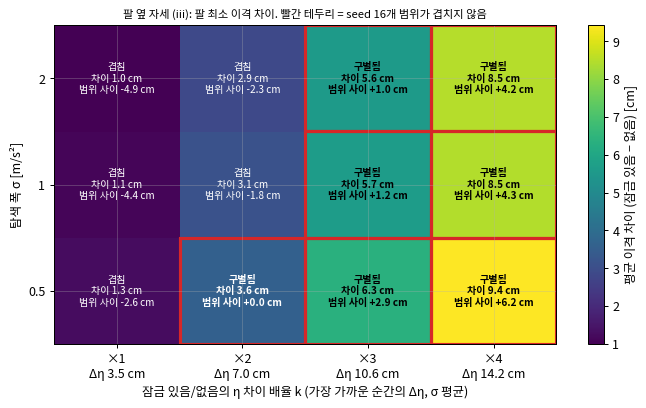

In [12]:
fig, ax = plt.subplots(figsize=(9, 4.6))
D = np.array([[RES2[(sg, k)]['diff'] * 100 for k in KSC] for sg in SIG2])
im = ax.imshow(D, cmap='viridis', origin='lower', aspect='auto')
for i, sg in enumerate(SIG2):
    for j, k in enumerate(KSC):
        r = RES2[(sg, k)]
        ok = r['sep'] > 0
        ax.text(j, i, '%s\n차이 %.1f cm\n범위 사이 %+.1f cm' % ('구별됨' if ok else '겹침', r['diff'] * 100, r['sep'] * 100),
                ha='center', va='center', fontsize=8, color='k' if D[i, j] > D.mean() else 'w', fontweight='bold' if ok else 'normal')
        if ok:
            ax.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, ec='C3', lw=2.5))
ax.set_xticks(range(len(KSC)))
ax.set_xticklabels(['×%d\nΔη %.1f cm' % (k, np.mean([RES2[(sg, k)]['de'] for sg in SIG2]) * 100) for k in KSC])
ax.set_yticks(range(len(SIG2))); ax.set_yticklabels(['%g' % s for s in SIG2])
ax.set_xlabel('잠금 있음/없음의 η 차이 배율 k (가장 가까운 순간의 Δη, σ 평균)'); ax.set_ylabel('탐색 폭 σ [m/s²]')
ax.set_title('팔 옆 자세 (iii): 팔 최소 이격 차이. 빨간 테두리 = seed 16개 범위가 겹치지 않음', fontsize=9)
fig.colorbar(im, ax=ax, label='평균 이격 차이 (잠금 있음 − 없음) [cm]')
plt.show()

**k = 1(16의 (iii) 그대로, Δη 3.4~3.5 cm):** 모든 σ에서 범위가 겹쳤다. 평균 차이는 +1.28(σ 0.5), +1.12(σ 1), +1.00 cm(σ 2)이고, 범위 사이는 −2.6~−4.9 cm였다. 같은 seed끼리 짝지으면 16 / 16, 15 / 16, 15 / 16이 양수다. **효과의 방향은 있지만, 크기가 seed 간 차이에 묻힌다.**

**구별되기 시작하는 곳:**
- σ = 0.5: k = 2(Δη 6.9 cm)부터 구별됐다. 다만 범위 사이가 +0.03 cm라 경계에 걸쳐 있다.
- σ = 1, 2: k = 3(Δη 10.6 cm)부터 구별됐다(범위 사이 +1.2, +1.0 cm).

**η 차이가 이격 차이로 얼마나 옮겨지나:** k = 1에서는 Δη의 약 29~38%만 평균 이격 차이로 나타났다(3.5 cm → 1.0~1.3 cm). k = 4에서는 60~67%였다(14.2 cm → 8.5~9.4 cm).

**seed 간 차이는 어디서 오나:** 잠금 없음의 팔 이격 범위는 σ = 0.5에서 0.046~0.093 m(4.7 cm 폭), σ = 1·2에서 6.0~6.4 cm 폭이다. 1D 장면의 seed 흩어짐(σ = 2에서 표준편차 0.38 cm)보다 훨씬 넓다. 경로가 팔 아래로 내려간 깊이(y 최솟값)가 seed마다 −0.024~−0.059 m(σ 0.5), −0.034~−0.086 m(σ 2)로 달랐다. 팔과 가장 가까운 스텝의 x도 0.82~0.91 m로 달라서, 팔의 어느 부분 옆에서 가장 가까워지는지가 seed마다 다르다. σ를 줄이면 범위가 좁아지고 평균 차이가 조금 커져, 구별에 필요한 Δη가 작아졌다.

**K를 늘리면 흩어짐이 줄까?** 1D(2.2절)에서는 K를 늘리면 seed 간 흩어짐이 줄었다. 같은 것을 k = 1, σ = 2에서 K = 1600으로 확인한다.

In [13]:
t0 = time.time()
GK2 = {lk: [run_mpc_opts(partial(cost_scaled, pz=POSES[lk], k=1), seed=s, sigma=2.0, K=1600) for s in SEEDS2] for lk in POSES}
print('실행 시간 %.0f s' % (time.time() - t0))
for K, src in [(S.K, {lk: [r['clr'] for r in G2[(2.0, 1, lk)]] for lk in POSES}),
               (1600, {lk: [pose_gaps(r['traj'], POSES[lk])[:, 1].min() for r in GK2[lk]] for lk in POSES})]:
    a, b = np.array(src['잠금 있음']), np.array(src['잠금 없음'])
    print('K = %4d: 잠금 있음 %s (표준편차 %.4f), 잠금 없음 %s (표준편차 %.4f), 평균 차이 %+.2f cm, 범위 사이 %+.2f cm'
          % (K, rng_str(a), a.std(), rng_str(b), b.std(), (a.mean() - b.mean()) * 100, (a.min() - b.max()) * 100))

실행 시간 218 s
K =  400: 잠금 있음 0.067~0.121 (표준편차 0.0151), 잠금 없음 0.056~0.116 (표준편차 0.0178), 평균 차이 +1.00 cm, 범위 사이 -4.94 cm
K = 1600: 잠금 있음 0.082~0.116 (표준편차 0.0087), 잠금 없음 0.069~0.108 (표준편차 0.0105), 평균 차이 +1.17 cm, 범위 사이 -2.65 cm


K를 400 → 1600으로 늘리면 표준편차가 1.51 → 0.87 cm(잠금 있음), 1.78 → 1.05 cm(잠금 없음)로 약 40% 줄었다. 평균 차이는 +1.00 → +1.17 cm로 거의 그대로이고, 범위 사이는 −4.94 → −2.65 cm로 여전히 겹쳤다. **K를 4배로 늘려도 k = 1의 η 차이는 구별되지 않았다.**

## 4. 실험 3 — 한 번의 실행 동안 ESS는 어떻게 바뀌는가

14의 기본 장면(사람 정지, 기준 자세, 균일 η = 0.10 m, w = 100, 기본 MPPI)에서 매 스텝 ESS를 기록한다. 비교를 위해 사람 비용을 뺀(목표 비용만) 실행도 같은 seed로 돌린다. 매 스텝 마지막 반복에서 **사람 비용이 0보다 큰 후보의 비율**도 함께 적는다. 이것이 "사람 비용이 켜진 정도"다. seed 8개.

In [14]:
SEEDS3 = range(8)
no_person = lambda Pf, offsets: np.zeros(Pf.shape[:-1])
t0 = time.time()
R3 = {name: [run_mpc_opts(human_cost=hc, seed=s) for s in SEEDS3] for name, hc in [('사람 있음', human_cost_uniform), ('사람 없음', no_person)]}
print('실행 시간 %.0f s\n' % (time.time() - t0))

def win_mean(name, key, a, b):
    return np.mean([r[key][a:b].mean() for r in R3[name]])

print('%-12s | %-9s | %-9s | %-16s | %-14s | %s' % ('스텝 구간', 'ESS 사람 있음', 'ESS 사람 없음', '사람 비용 후보 비율', '로봇-사람 간격 [m]', '로봇 x [m]'))
for a, b in [(0, 5), (5, 10), (10, 15), (15, 20), (20, 25), (25, 30), (30, 60), (60, 100)]:
    gap = np.mean([segment_gaps(r['traj'][1 + a:1 + b]).min(-1).mean() for r in R3['사람 있음']])
    print('%3d~%-3d (%.2f~%.2f s) | %-9.0f | %-9.0f | %-16.2f | %-14.3f | %.2f' % (a, b, a * S.DT, b * S.DT, win_mean('사람 있음', 'ess', a, b), win_mean('사람 없음', 'ess', a, b),
          win_mean('사람 있음', 'human_frac', a, b), gap, np.mean([r['traj'][1 + a:1 + b, 0].mean() for r in R3['사람 있음']])))
du = lambda name, a, b: np.mean([np.linalg.norm(np.diff(r['us'], axis=0), axis=1)[a:b].mean() for r in R3[name]])
print('\n명령 변화량 평균 [m/s²], 스텝 0~20: 사람 있음 %.2f, 사람 없음 %.2f | 스텝 20~100: 사람 있음 %.2f, 사람 없음 %.2f'
      % (du('사람 있음', 0, 19), du('사람 없음', 0, 19), du('사람 있음', 19, 99), du('사람 없음', 19, 99)))

실행 시간 15 s

스텝 구간        | ESS 사람 있음 | ESS 사람 없음 | 사람 비용 후보 비율      | 로봇-사람 간격 [m]   | 로봇 x [m]
  0~5   (0.00~0.25 s) | 12        | 19        | 0.55             | 0.754          | 0.05
  5~10  (0.25~0.50 s) | 28        | 40        | 0.46             | 0.515          | 0.30
 10~15  (0.50~0.75 s) | 45        | 54        | 0.41             | 0.217          | 0.76
 15~20  (0.75~1.00 s) | 57        | 58        | 0.43             | 0.130          | 1.28
 20~25  (1.00~1.25 s) | 58        | 59        | 0.04             | 0.210          | 1.67
 25~30  (1.25~1.50 s) | 60        | 59        | 0.07             | 0.391          | 1.93
 30~60  (1.50~3.00 s) | 59        | 59        | 0.11             | 0.484          | 2.03
 60~100 (3.00~5.00 s) | 58        | 58        | 0.11             | 0.454          | 2.00

명령 변화량 평균 [m/s²], 스텝 0~20: 사람 있음 1.29, 사람 없음 1.33 | 스텝 20~100: 사람 있음 1.43, 사람 없음 1.45


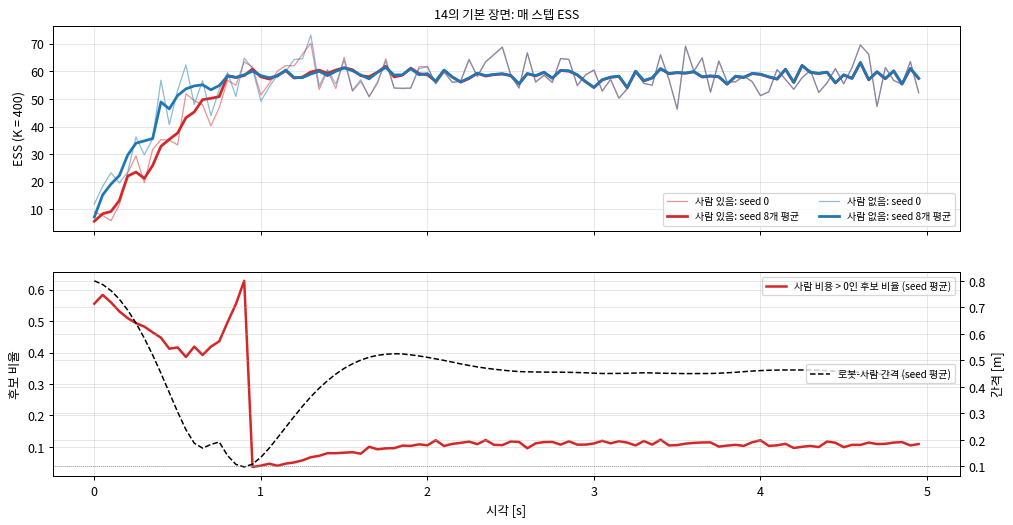

In [15]:
t = np.arange(S.STEPS) * S.DT
fig, axs = plt.subplots(2, 1, figsize=(13, 6.5), sharex=True)
ax = axs[0]
for name, col in [('사람 있음', 'C3'), ('사람 없음', 'C0')]:
    E = np.array([r['ess'] for r in R3[name]])
    ax.plot(t, E[0], color=col, lw=1, alpha=0.5, label=f'{name}: seed 0')
    ax.plot(t, E.mean(0), color=col, lw=2.2, label=f'{name}: seed 8개 평균')
ax.set_ylabel('ESS (K = 400)'); ax.legend(fontsize=8, ncol=2); ax.set_title('14의 기본 장면: 매 스텝 ESS', fontsize=10)
ax = axs[1]
H = np.array([r['human_frac'] for r in R3['사람 있음']])
G = np.array([segment_gaps(r['traj'][1:]).min(-1) for r in R3['사람 있음']])
ax.plot(t, H.mean(0), 'C3', lw=2, label='사람 비용 > 0인 후보 비율 (seed 평균)')
ax.set_ylabel('후보 비율'); ax.set_xlabel('시각 [s]')
ax2 = ax.twinx(); ax2.plot(t, G.mean(0), 'k--', lw=1.2, label='로봇-사람 간격 (seed 평균)'); ax2.axhline(S.ETA0, color='gray', lw=0.6, ls=':')
ax2.set_ylabel('간격 [m]')
ax.legend(fontsize=8, loc='upper right'); ax2.legend(fontsize=8, loc='center right')
plt.show()

| 구간 | ESS (사람 있음 / 없음) | 사람 비용이 켜진 후보 | 로봇-사람 간격 |
|---|---|---|---|
| 0~0.25 s | 12 / 19 | 55% | 0.75 m |
| 0.25~0.5 s | 28 / 40 | 46% | 0.52 m |
| 0.5~0.75 s | 45 / 54 | 41% | 0.22 m |
| 0.75~1.0 s (가장 가까이 지남) | 57 / 58 | 43% | 0.13 m |
| 1.0 s 이후 | 58~60 / 58~59 | 4~11% | 0.21~0.48 m |

- **사람 비용은 다가가는 동안(0~0.75 s) ESS를 17~37% 줄였다.** 이때 로봇은 아직 사람에게서 0.2~0.75 m 떨어져 있지만, 1.5 s 앞까지 보는 후보의 41~55%가 사람 비용을 받는다.
- **가장 가까이 지나는 0.75~1.0 s에는 ESS 차이가 없었다**(57 / 58). 그림에서 사람 비용이 켜진 후보 비율은 이 구간 끝(약 0.9 s)에 0.6까지 오른 뒤 지나치자마자 0.04로 떨어진다. 가설은 "사람 비용이 켜진 구간에 ESS가 줄어든다"였지만, 이 장면에서는 다가가는 구간에서만 나왔다.
- **ESS가 처음에 작은 것은 사람이 없어도 같다**(19 → 59). 목표가 멀 때는 목표 비용의 흩어짐이 커서 ESS가 작다. 초반 ESS를 정하는 것은 사람보다 목표 거리다.
- **명령 변화량은 사람 유무로 거의 달라지지 않았다**(0~1 s: 1.29 / 1.33, 1 s 이후: 1.43 / 1.45 m/s²). 사람 비용이 ESS를 줄인 구간에서도 명령이 더 흔들리지는 않았다.
- 목표에 도착한 뒤에도 ESS는 K = 400 중 약 58이다. 이 장면의 기본 설정(σ = 2, β = 1)에서는 가중치가 늘 후보의 15% 정도에 실려 있다.

## 5. 정리

| 가설 | 결과 |
|---|---|
| β가 작을수록, 비용 차이가 클수록 ESS가 작고 명령이 흔들린다 | **나옴(1D).** σ = 2에서 β 0.1 → 10: ESS 2 → 127, 명령 변화량 3.44 → 0.72(w = 100). w = 100이 18.75보다 ESS가 작다(13 vs 25). **2D 실행(4절)에서는 반만 나옴:** 사람 비용은 다가가는 동안 ESS를 17~37% 줄였지만, 명령 변화량은 같았다 |
| σ가 클수록 잡음 편향이 크다 | **w = 100에서 나옴**(σ 0.25 → 3: +0.07 → +1.84 cm). **w = 18.75에서는 σ ≥ 0.5에서만 나옴.** σ = 0.25에서 다시 커지는 것(15의 이상 결과)은 ESS가 233으로 커져 편향과 흩어짐이 다시 커지는 영역에 들어갔기 때문으로 보인다 |
| K가 클수록 편향의 seed 흩어짐이 줄어든다 | **나옴.** 1D: 표준편차 1.84 → 0.09 cm(K 50 → 1600, w = 100). 편향 자체도 +2.68 → +1.12 cm로 줄었지만 0이 되지는 않았다. 2D 팔 옆: K 400 → 1600에서 1.5~1.8 → 0.9~1.0 cm |
| η 차이가 편향의 흩어짐보다 커야 구별되고, 현재 팔 η 차이는 그 경계 근처 또는 아래다 | **나옴, 경계 아래.** 현재 Δη 3.5 cm는 σ 0.5~2 모두에서 범위가 겹친다. 구별에는 Δη 6.9 cm(σ = 0.5, 경계)~10.6 cm(σ = 1, 2)가 필요했다. 즉 현재의 2~3배다 |

**방향별 질량 효과가 구별되는 조건(이 장면, seed 16개, K = 400, β = 1):**
- 잠금 있음/없음의 η 차이가 σ = 0.5에서 약 7 cm 이상, σ = 1~2에서 약 10.6 cm 이상이어야 했다.
- 같은 seed끼리 비교하면 Δη 3.5 cm에서도 15~16 / 16이 같은 방향이었다. 효과는 있지만 크기(약 1 cm)가 seed 간 경로 차이(범위 5~6 cm)보다 작다.
- 그 흩어짐의 주된 원천은 1D에서 본 잡음 편향의 흩어짐(0.4 cm)이 아니었다. 경로가 팔 아래로 얼마나 내려가는지, 가장 가까운 순간이 어느 스텝에 걸리는지가 seed마다 다른 것이다. K를 4배로 늘려도 표준편차는 약 40%만 줄었다.

**15·16과의 연결**
- 15의 잡음 편향(1~2.4 cm)은 σ가 커서 생기는 편향이다. 이 노트에서 w = 100, β = 1일 때 σ = 2에서 +1.56 cm였고, σ를 줄이거나 K를 늘리면 줄었다.
- 15의 σ = 0.25 이상 결과는 ESS로 설명된다. σ를 줄이면 s/β가 작아져 ESS가 커지고(233), 그 영역에서는 편향과 흩어짐이 다시 커진다. 음의 편향(−0.4~−0.6 cm, w = 18.75, ESS 130 안팎)은 설명하지 못했다.
- 16의 "η 차이가 잡음에 묻힘"은 수치로 확인됐다. 다만 묻히게 하는 것은 1D의 편향보다 2D 경로의 seed 간 차이다.

**cuRobo 설정과의 관계(22에서 확인):** cuRobo 프로토타입의 β = 0.1은 이 노트 격자의 가장 왼쪽 열(ESS 1~24)에 해당한다. 이 노트는 가중평균 출력만 다뤘고, BEST 출력에서도 같은지는 22에서 본다.

**이 노트의 범위:** 1D 정지 장면 seed 8개, 팔 옆 자세 seed 16개, 14의 기본 장면 seed 8개. 형상 비용 합치기와 비용 불연속(18), 필요 이격 거리(19)는 다루지 않았다.

## 핵심 정리

- ESS = (Σw)²/Σw²는 가중치가 실제로 몇 개 후보에 실려 있는지를 나타낸다. 1이면 후보 하나, K이면 모두 같다.
- ESS는 β 하나가 아니라 **비용 흩어짐 s와 β의 비**로 정해진다(정규분포 비용이면 ESS/K ≈ exp(−(s/β)²)). β를 줄이거나, σ나 w를 키워 비용 차이가 커지면 ESS가 준다.
- ESS가 작으면(β가 작으면) 명령이 더 흔들린다. ESS가 크면(이 노트에서는 약 200 / 400 이상) 갱신에 비용 차이가 적게 반영되고, 이격의 편향과 seed 흩어짐이 커졌다.
- 잡음 편향은 σ가 클수록 크고, K를 늘리면 편향과 seed 흩어짐이 모두 줄지만 편향은 0이 되지 않는다. σ를 줄이면 ESS가 커지므로 σ와 β는 함께 정해야 한다.
- 팔 옆 자세에서 방향별 질량의 η 차이(3.5 cm)는 이격 차이 약 1 cm로만 나타나 seed 범위(5~6 cm)에 묻힌다. 구별되려면 이 장면에서 η 차이가 7~10.6 cm(현재의 2~3배) 필요했다.
- 2D에서 seed 간 차이는 주로 경로 높이와 가장 가까운 순간의 위치에서 온다. K를 4배로 늘려도 약 40%만 줄었다.

## 확인 문제

<details><summary>1. (계산) 후보 4개의 정규화된 가중치가 0.5, 0.25, 0.25, 0일 때 ESS는? 0.4, 0.3, 0.2, 0.1이면?</summary>

1 / (0.25 + 0.0625 + 0.0625 + 0) = **2.67**. 1 / (0.16 + 0.09 + 0.04 + 0.01) = **3.33**. 가중치가 고를수록 4에 가깝다.
</details>

<details><summary>2. (보기) 다른 것은 그대로 두고 β를 1 → 0.1로 줄이면? (a) ESS가 늘고 명령이 덜 흔들린다 (b) ESS가 줄고 명령이 더 흔들린다 (c) 둘 다 그대로다</summary>

**(b)**. 가중치가 $\exp(-J/\beta)$라서 β가 작으면 가장 싼 몇 개에 몰린다. 그 몇 개는 잡음으로 뽑힌 후보라 스텝마다 바뀐다. 2.1절에서 σ = 2, w = 100일 때 ESS가 13 → 2로 줄고 명령 변화량이 1.86 → 3.44로 커졌다.
</details>

<details><summary>3. (계산) 후보 비용이 표준편차 s = 2로 흩어져 있고 β = 1이면 ESS/K는 대략? β = 4이면?</summary>

exp(−(2/1)²) = exp(−4) ≈ **0.018**(K = 400이면 약 7). exp(−(2/4)²) = exp(−0.25) ≈ **0.78**(약 311).
</details>

<details><summary>4. (보기) 3절에서 K를 4배로 늘려도 k = 1의 seed 범위가 겹친 이유로 이 노트가 확인한 것은? (a) 후보가 적어서 (b) 팔 옆을 지나는 경로의 높이(y 최솟값)가 seed마다 다르다 (c) β가 너무 작아서</summary>

**(b)**. 잠금 없음에서 경로가 팔 아래로 내려간 깊이가 seed마다 2.4~5.9 cm(σ = 0.5)로 달랐고, 가장 가까운 스텝의 x도 0.82~0.91 m로 달랐다. K를 400 → 1600으로 늘리면 표준편차는 약 40% 줄었지만 범위는 여전히 겹쳤다.
</details>

## 다음 노트

**[18 · 여러 형상의 비용 합치기](18_shape_combine.ipynb)**: 사람 몸의 형상별 η 비용을 가장 가까운 형상 하나(min), 모두 더하기(sum), 가장 큰 것(max)으로 합칠 때 비용 지형과 MPPI 회피가 어떻게 달라지는지 본다. 16의 몸통 그늘과 가장 가까운 형상이 바뀌는 곳의 비용 불연속을 여기서 다룬다.